# 05 · Hồi quy điểm Logistic Regression

Phần của Tuananh dùng Linear Regression với đầu ra liên tục là xác suất `Response=1` từ bộ phân loại Logistic nguồn. Nhóm dùng bộ điểm bàn giao cố định ở `data/processed/logistic_scores/` cho cả hai mô hình hồi quy và cả hai nhánh đầu vào.

Điểm train được tạo ngoài fold theo nhóm khách hàng trùng. Điểm validation do pipeline Logistic fit trên toàn bộ train dự đoán. Hàm đọc kiểm tra manifest và ghép điểm theo `processed_row`, đồng thời đối chiếu `source_row` và `Response` để xác nhận đúng bản ghi.

Mỗi tỷ lệ 80:20, 70:30 và 60:40 chạy hai biểu diễn, gồm bộ đặc trưng đầy đủ và PCA giữ một phần ba số chiều sau mã hóa. Mỗi pipeline chỉ fit trên train. Linear Regression dùng bình phương tối thiểu với hệ số chặn mặc định.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display

root = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "src" / "regression.py").is_file()
)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src import config
from src.regression import evaluate_linear_regression

sns.set_theme(style="whitegrid")
figures = config.FIGURES_REGRESSION_DIR
figures.mkdir(parents=True, exist_ok=True)
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)
metrics, predictions = evaluate_linear_regression()
metrics.to_csv(config.TABLES_DIR / "linear_regression_metrics.csv", index=False)

## Kết quả train và validation

RMSE, MAE và R² đo mức độ tái tạo điểm của Logistic nguồn. Các độ đo này mô tả sai số so với điểm nguồn ở từng tỷ lệ chia. Đánh giá khả năng phân loại khách hàng hưởng ứng dùng nhãn Response trong notebook 04.

Linear Regression có đầu ra số thực. Bảng ghi số dự đoán vượt ngoài đoạn [0, 1], tính theo đầu ra trực tiếp của mô hình.

In [2]:
display(metrics[[
    "split", "representation", "partition", "rows", "n_features",
    "rmse", "mae", "r2", "predictions_outside_unit_interval"
]].round(4))

scenario = ["split", "representation"]
validation = metrics.loc[metrics["partition"].eq("validation")].copy()
train = metrics.loc[metrics["partition"].eq("train")]
comparison = validation.merge(
    train[scenario + ["rmse"]].rename(columns={"rmse": "train_rmse"}),
    on=scenario, validate="one_to_one",
)
comparison["validation_minus_train_rmse"] = comparison["rmse"] - comparison["train_rmse"]
display(comparison[scenario + [
    "train_rmse", "rmse", "validation_minus_train_rmse", "mae", "r2"
]].round(4))

,split,representation,partition,rows,n_features,rmse,mae,r2,predictions_outside_unit_interval
0,80_20,full,train,1430,37,0.1075,0.0825,0.7975,337
1,80_20,full,validation,358,37,0.0963,0.0731,0.7881,76
2,80_20,pca_one_third,train,1430,12,0.1257,0.0904,0.7233,310
3,80_20,pca_one_third,validation,358,12,0.1109,0.0814,0.7193,66
4,70_30,full,train,1250,37,0.1055,0.0804,0.8034,290
5,70_30,full,validation,538,37,0.1039,0.0786,0.7841,113
6,70_30,pca_one_third,train,1250,12,0.1255,0.0884,0.7218,262
7,70_30,pca_one_third,validation,538,12,0.1221,0.0903,0.7017,94
8,60_40,full,train,1072,37,0.1113,0.0862,0.7903,266
9,60_40,full,validation,716,37,0.1090,0.0858,0.7820,161


,split,representation,train_rmse,rmse,validation_minus_train_rmse,mae,r2
0,80_20,full,0.1075,0.0963,-0.0112,0.0731,0.7881
1,80_20,pca_one_third,0.1257,0.1109,-0.0148,0.0814,0.7193
2,70_30,full,0.1055,0.1039,-0.0017,0.0786,0.7841
3,70_30,pca_one_third,0.1255,0.1221,-0.0034,0.0903,0.7017
4,60_40,full,0.1113,0.1090,-0.0023,0.0858,0.7820
5,60_40,pca_one_third,0.1350,0.1285,-0.0065,0.0952,0.6970


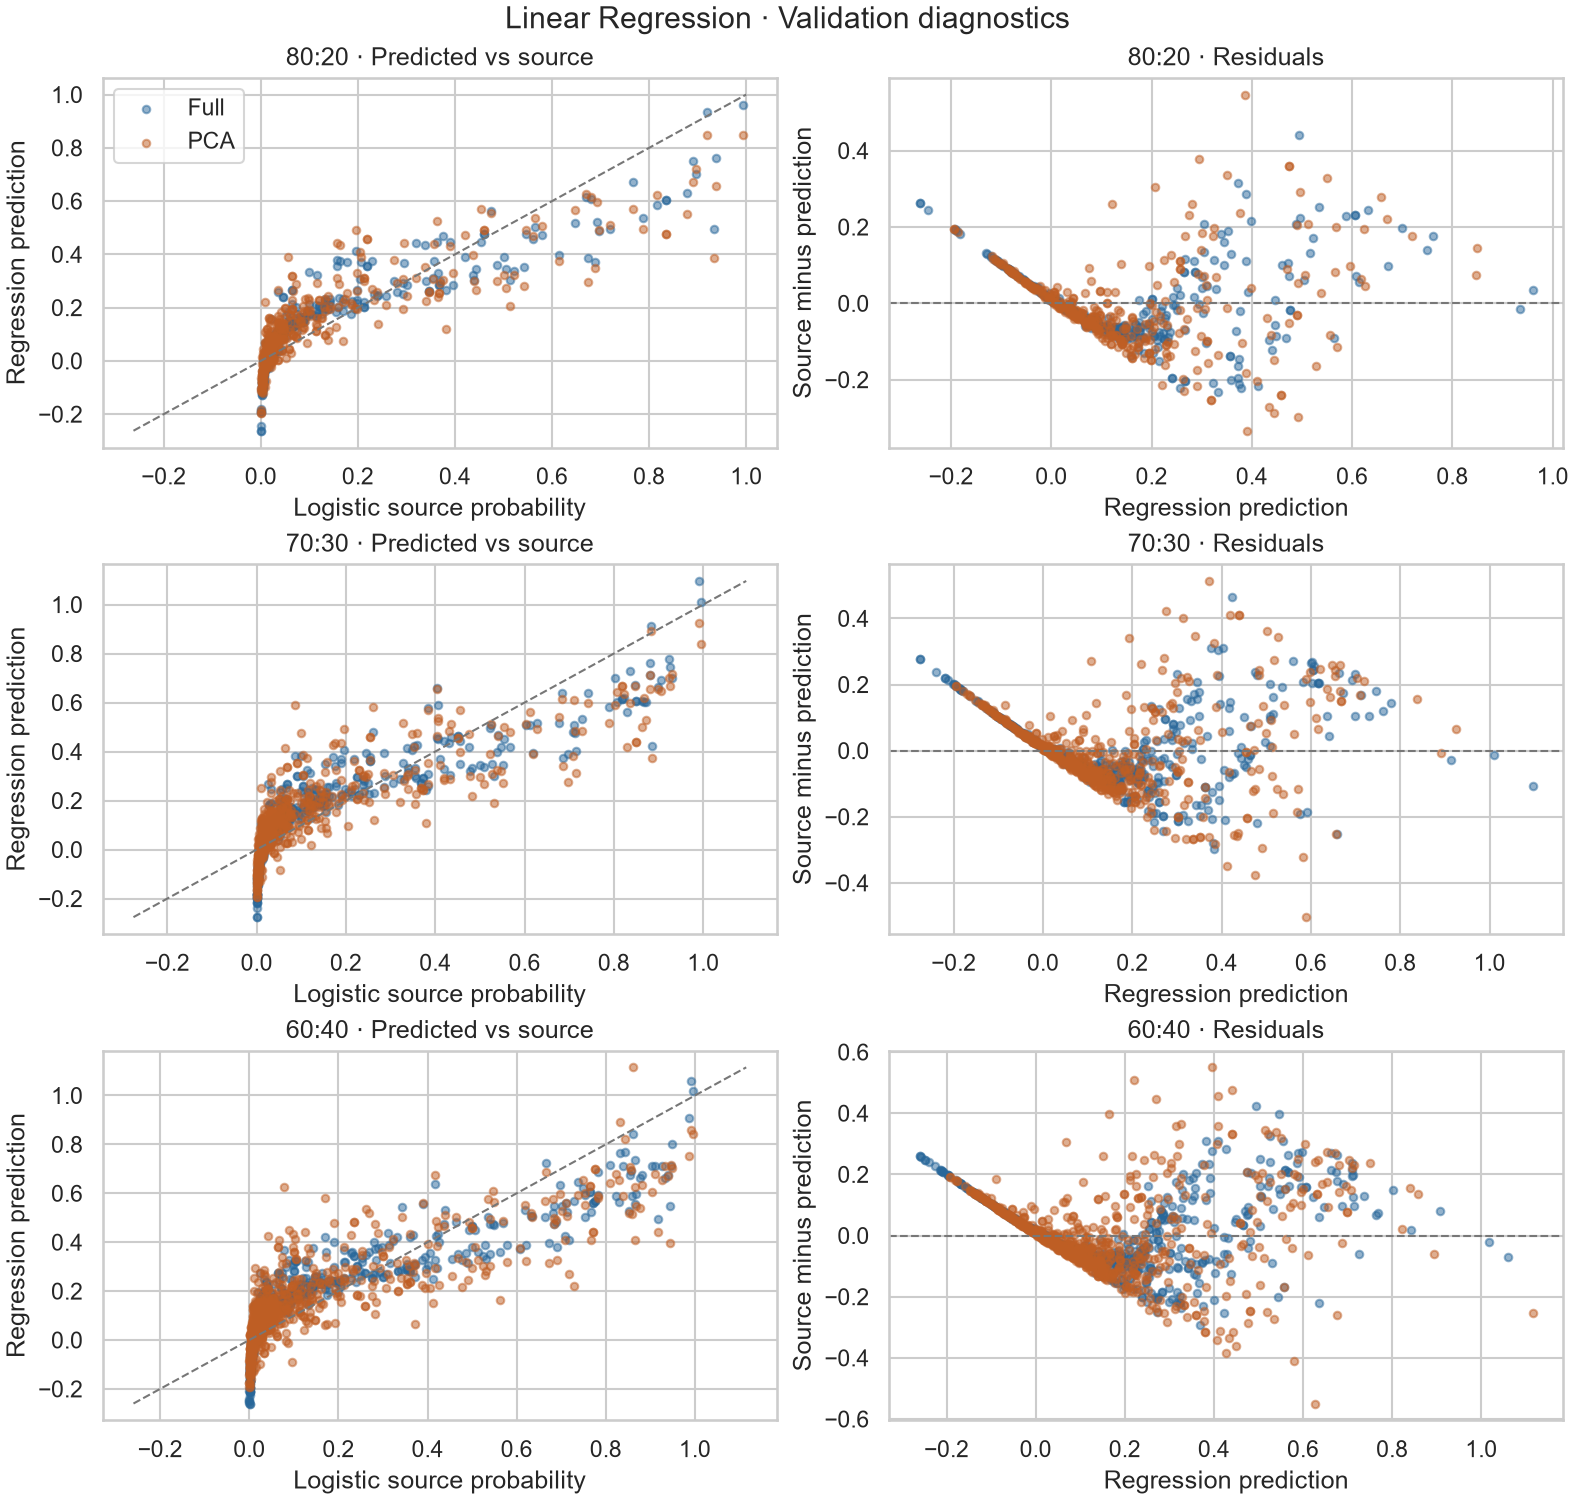

In [3]:
colors = {"full": "#28679A", "pca_one_third": "#BF5E24"}
names = {"full": "Full", "pca_one_third": "PCA"}
fig, axes = plt.subplots(3, 2, figsize=(10.5, 10), layout="constrained")
for row, split in enumerate(("80_20", "70_30", "60_40")):
    selected = predictions.loc[predictions["split"].eq(split)]
    predicted_ax, residual_ax = axes[row]
    for representation, values in selected.groupby("representation", sort=False):
        style = {"s": 13, "alpha": 0.5, "color": colors[representation], "label": names[representation]}
        predicted_ax.scatter(values["source_probability"], values["prediction"], **style)
        residual_ax.scatter(
            values["prediction"], values["source_probability"] - values["prediction"], **style
        )
    lower = min(0, selected["prediction"].min())
    upper = max(1, selected["prediction"].max())
    predicted_ax.plot([lower, upper], [lower, upper], color="#777777", linestyle="--", linewidth=1)
    residual_ax.axhline(0, color="#777777", linestyle="--", linewidth=1)
    ratio = split.replace("_", ":")
    predicted_ax.set(
        title=f"{ratio} · Predicted vs source", xlabel="Logistic source probability",
        ylabel="Regression prediction",
    )
    residual_ax.set(
        title=f"{ratio} · Residuals", xlabel="Regression prediction",
        ylabel="Source minus prediction",
    )
axes[0, 0].legend(loc="upper left")
fig.suptitle("Linear Regression · Validation diagnostics")
fig.savefig(figures / "linear_regression_diagnostics.png", dpi=config.FIGURE_DPI)
plt.show()
plt.close(fig)

## Nhận xét kết quả

Bộ đặc trưng đầy đủ đạt RMSE validation lần lượt 0,0963, 0,1039 và 0,1090 ở các tỷ lệ 80:20, 70:30 và 60:40. R² tương ứng là 0,7881, 0,7841 và 0,7820. Nhánh PCA có RMSE cao hơn ở cả ba tỷ lệ, từ 0,1109 đến 0,1285. PCA giữ các hướng có phương sai lớn trong đầu vào, trong khi quan hệ với điểm Logistic còn có thể nằm ở những hướng bị loại bỏ.

Biểu đồ phần dư có cấu trúc theo mức dự đoán. Một đường hồi quy tuyến tính chỉ xấp xỉ được hàm xác suất phi tuyến của Logistic. Trên nhánh đầy đủ, có 76, 113 và 161 dự đoán validation ngoài đoạn [0, 1] tương ứng ba tỷ lệ. Kết quả cho thấy mô hình tái tạo được một phần lớn biến thiên của điểm nguồn, đồng thời còn sai lệch có hệ thống.

RMSE validation thấp hơn RMSE train ở cả sáu thí nghiệm. Điểm train được tạo bởi nhiều mô hình Logistic ngoài fold, còn điểm validation được tạo bởi một mô hình Logistic học toàn bộ train. Chênh lệch lỗi cần được diễn giải cùng cách tạo hai bộ điểm này khi nhận xét khả năng khái quát.

## Ghép kết quả mô hình hồi quy của ChinhBui

Bảng `linear_regression_metrics.csv` ghi mô hình, tỷ lệ chia, biểu diễn, tập đánh giá, số chiều, seed, RMSE, MAE và R². Ghép với bảng KNN Regressor hoặc MLP Regressor theo cùng tỷ lệ chia và biểu diễn đầu vào. Hai bên dùng chung `train_oof_scores.csv` và `validation_scores.csv` trong mỗi tỷ lệ.